# Giorno 5 — Apprendimento non supervisionato e progetto finale scikit-learn

> Linguaggio degli esempi: Python 3 (scikit-learn ≥ 1.4, NumPy, pandas, matplotlib, SciPy). Ogni modulo segue la struttura: Spiegazione teorica → Esempi teorici di utilizzo → Esempi di codice → Esercizi.
> Prerequisiti dai giorni precedenti: apprendimento non supervisionato (Giorno 1), scaling e regola d'oro (Giorno 2), kernel (Giorno 3), Pipeline e GridSearchCV (Giorno 4).

# 5.1 Riduzione della dimensionalità e PCA

## Spiegazione teorica

**Dimensionalità** = numero di feature. Digits ha 64 feature (pixel), un dataset di testi può averne decine di migliaia.

**Perché ridurla**
- **Maledizione della dimensionalità:** con molte feature i dati diventano "radi": i punti sono tutti lontani tra loro, le distanze perdono significato (KNN, SVM e clustering peggiorano) e servono moltissimi campioni per coprire lo spazio.
- **Visualizzazione:** possiamo disegnare solo 2 o 3 dimensioni.
- **Velocità e memoria:** meno colonne = addestramento più rapido.
- **Rumore e ridondanza:** feature fortemente correlate (multicollinearità) dicono la stessa cosa; riassumerle può migliorare la generalizzazione.

**Due strategie**
- **Selezione delle feature:** si tengono alcune colonne originali e si scartano le altre (Lasso, `SelectKBest`, importanze).
- **Estrazione delle feature:** si creano **nuove** colonne che combinano quelle originali. La PCA fa questo.

**PCA — Principal Component Analysis (Analisi delle Componenti Principali)**
- Idea: trovare nuovi assi, le **componenti principali**, lungo i quali i dati sono più "sparpagliati" (hanno più **varianza**). Dove i dati variano molto c'è informazione; dove variano poco c'è poco da dire.
- Le componenti sono:
  - **ordinate**: la prima cattura la massima varianza possibile, la seconda la massima tra quelle rimaste, e così via;
  - **perpendicolari** tra loro (ortogonali): ognuna porta informazione nuova, non ripetuta;
  - **combinazioni lineari** delle feature originali: es. `PC1 = 0.52·lunghezza_petalo + 0.58·larghezza_petalo + …`. I coefficienti si trovano in `components_`.
- Ridurre la dimensionalità = tenere solo le prime k componenti e **proiettare** i dati su di esse.
- Il calcolo usa una tecnica dell'algebra lineare chiamata **SVD** (Singular Value Decomposition, decomposizione ai valori singolari); non serve conoscerla per usare la PCA.

**Quanta informazione si conserva**
- La **varianza spiegata** indica quanta della variabilità totale dei dati viene “catturata” da una componente principale (o da un gruppo di componenti). È il modo in cui la PCA ti dice quanto un asse è importante.
- `explained_variance_ratio_`: frazione di varianza spiegata da ogni componente (es. `[0.73, 0.23]` → le prime due componenti conservano il 96% della varianza).
- Somma cumulativa (`np.cumsum`): quante componenti servono per arrivare all'80%, 90%, 95%.
- **Scree plot:** grafico della varianza spiegata per componente; si cerca il punto in cui la curva si appiattisce.

**Parametro `n_components`**
- intero → numero esatto di componenti (es. 2 per visualizzare);
- decimale tra 0 e 1 → il numero minimo di componenti che spiega quella frazione di varianza (es. `0.95`);
- `"mle"` → stima automatica; `None` → tutte le componenti.
- Altri parametri: `whiten=True` (scala le componenti a varianza 1), `svd_solver` (`"auto"`, `"full"`, `"arpack"`, `"randomized"` per dataset grandi), `random_state`.

**Regole pratiche**
- **Standardizzare prima:** la varianza dipende dalle unità di misura; senza scaling vince la feature con i numeri più grandi.
- La PCA è un **transformer non supervisionato**: ignora y. Segue la regola d'oro (fit sul training) e si inserisce in una Pipeline.
- `inverse_transform` ricostruisce i dati originali dalle componenti: la ricostruzione è approssimata, perché l'informazione delle componenti scartate è persa.
- Contro: le nuove feature sono meno interpretabili ("PC3" non ha un significato immediato).
- **IncrementalPCA:** versione che elabora i dati a blocchi (`batch_size`, `partial_fit`), per dataset troppo grandi per la memoria.

## Esempi teorici di utilizzo

- **Visualizzare un dataset con decine di feature** in un grafico 2D per vedere se le classi sono separate o se esistono gruppi.
- **Compressione:** immagini o segnali con centinaia di valori riassunti in poche componenti prima di un modello.
- **Questionari:** 40 domande correlate riassunte in pochi "fattori" (es. soddisfazione per il prezzo, per il servizio).
- **Accelerare un modello lento** (SVM, KNN) su dati ad alta dimensionalità, spesso con perdita minima di accuratezza.

## Esempi di codice

### Base
Cosa mostra: ridurre Iris da 4 a 2 dimensioni e visualizzarlo.

Varianza spiegata: [0.73  0.229]
Totale conservato: 0.958
PC1 = {'sepal length (cm)': 0.52, 'sepal width (cm)': -0.27, 'petal length (cm)': 0.58, 'petal width (cm)': 0.56}
PC2 = {'sepal length (cm)': 0.38, 'sepal width (cm)': 0.92, 'petal length (cm)': 0.02, 'petal width (cm)': 0.07}


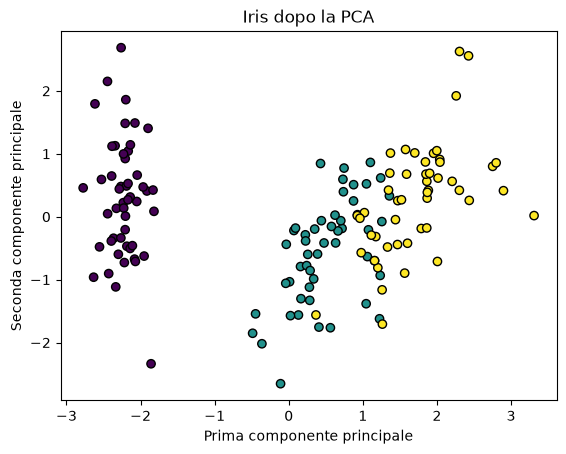

In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

iris = load_iris()
X_scaled = StandardScaler().fit_transform(iris.data)    # prima lo scaling (qui nessun test set: solo esplorazione)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)                     # da (150, 4) a (150, 2)

print("Varianza spiegata:", pca.explained_variance_ratio_.round(3))          # [0.73 0.229]
print("Totale conservato:", pca.explained_variance_ratio_.sum().round(3))
print("PC1 =", {f: round(float(c), 2) for f, c in zip(iris.feature_names, pca.components_[0])})   # ricetta della PC1
print("PC2 =", {f: round(float(c), 2) for f, c in zip(iris.feature_names, pca.components_[1])})   # ricetta della PC2

plt.scatter(X_pca[:, 0], X_pca[:, 1], c=iris.target, cmap="viridis", edgecolor="k")
plt.xlabel("Prima componente principale"); plt.ylabel("Seconda componente principale")
plt.title("Iris dopo la PCA"); plt.show()

- Con 2 componenti conserviamo circa il 96% della varianza: il grafico 2D è una buona sintesi dei 4 valori originali.
- `components_[0]` mostra quanto ogni feature contribuisce alla prima componente.
- Le specie restano ben separate anche se la PCA non ha mai visto le etichette (il colore lo aggiungiamo noi nel grafico).

### Intermedio
Cosa mostra: scegliere quante componenti tenere e vedere cosa si perde nella ricostruzione.

Componenti per il 95% della varianza: 29
Con n_components=0.95: 29 componenti


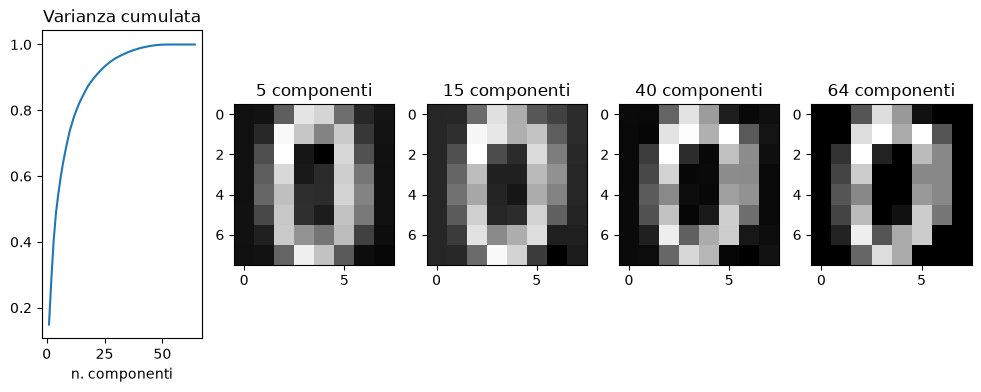

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA

digits = load_digits()
X = digits.data                                       # 64 pixel con valori da 0 a 16 (stessa scala)

pca_tutte = PCA().fit(X)
# print(pca_tutte.explained_variance_ratio_)
cumulata = np.cumsum(pca_tutte.explained_variance_ratio_)
# print(cumulata)
print(f"Componenti per il 95% della varianza:", np.argmax(cumulata >= 0.95) + 1)

pca95 = PCA(n_components=0.95).fit(X)                 # decimale = frazione di varianza da conservare
print("Con n_components=0.95:", pca95.n_components_, "componenti")

fig, axes = plt.subplots(1, 5, figsize=(12, 4))
axes[0].plot(range(1, 65), cumulata); axes[0].set_title("Varianza cumulata")
axes[0].set_xlabel("n. componenti")
for ax, k in zip(axes[1:], [5, 15, 40, 64]):
    pca_k = PCA(n_components=k).fit(X)
    ricostruita = pca_k.inverse_transform(pca_k.transform(X[:1]))   # comprimi e decomprimi
    ax.imshow(ricostruita.reshape(8, 8), cmap="gray"); ax.set_title(f"{k} componenti")
plt.show()

- Qui i pixel hanno già tutti la stessa scala (0–16), quindi lo scaling non è indispensabile.
- Bastano 29 componenti su 64 per conservare il 95% della varianza: circa metà dei dati è ridondante.
- Con 5 componenti la cifra ricostruita è sfocata; con 40 è quasi identica all'originale.

### Avanzato
Cosa mostra: PCA dentro una Pipeline e scelta di `n_components` con GridSearchCV.

In [5]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression

X, y = load_digits(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

pipeline = Pipeline([("scaler", StandardScaler()),
                     ("pca", PCA()),                                  # fit solo sui dati di training
                     ("clf", LogisticRegression(max_iter=2000))])
grid = GridSearchCV(pipeline, {"pca__n_components": [2, 5, 10, 20, 30, 0.95]}, cv=5, n_jobs=-1)
grid.fit(X_train, y_train)

for n, media in zip(grid.cv_results_["param_pca__n_components"], grid.cv_results_["mean_test_score"]):
    print(f"n_components={n:<5g} accuratezza CV={media:.3f}")
print("Migliore:", grid.best_params_, "| test:", round(grid.score(X_test, y_test), 3))
print("Componenti usate:", grid.best_estimator_["pca"].n_components_)

n_components=2     accuratezza CV=0.561
n_components=5     accuratezza CV=0.823
n_components=10    accuratezza CV=0.883
n_components=20    accuratezza CV=0.950
n_components=30    accuratezza CV=0.962
n_components=0.95  accuratezza CV=0.967
Migliore: {'pca__n_components': 0.95} | test: 0.96
Componenti usate: 40


- Con 2 componenti (ottime per il grafico) l'accuratezza è bassa: per classificare servono più informazioni.
- Da circa 20 componenti in su l'accuratezza si avvicina a quella con tutti i 64 pixel; il migliore è `0.95`, che sui dati standardizzati corrisponde a 40 componenti.
- Il numero di componenti è un iperparametro come gli altri: si sceglie con la cross-validation, non a occhio.

## Esercizi

### Facile
Obiettivo: su `load_wine()` applica `StandardScaler` e `PCA(n_components=2)`, stampa la varianza spiegata dalle due componenti e disegna lo scatter colorato per classe. Ripeti **senza** scaling e confronta i due grafici: quale feature domina la PCA non scalata e perché?

Con scaling - varianza spiegata: [0.362 0.192]
Senza scaling - varianza spiegata: [0.998 0.002]


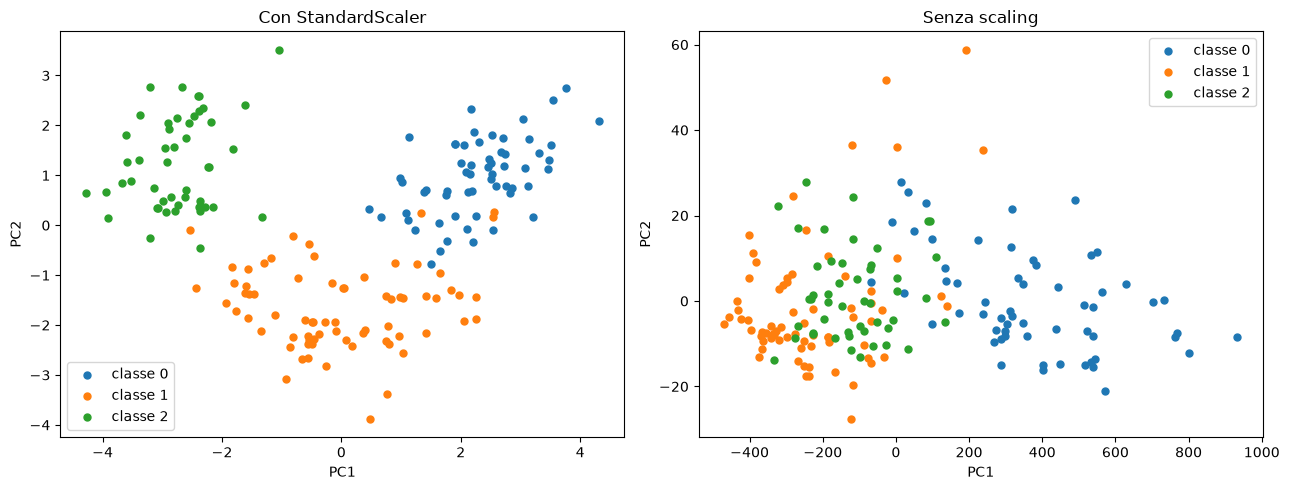

Feature dominante senza scaling: proline - peso = 1.0

Deviazione standard delle feature grezze:
{'alcohol': np.float64(0.81), 'malic_acid': np.float64(1.11), 'ash': np.float64(0.27), 'alcalinity_of_ash': np.float64(3.33), 'magnesium': np.float64(14.24), 'total_phenols': np.float64(0.62), 'flavanoids': np.float64(1.0), 'nonflavanoid_phenols': np.float64(0.12), 'proanthocyanins': np.float64(0.57), 'color_intensity': np.float64(2.31), 'hue': np.float64(0.23), 'od280/od315_of_diluted_wines': np.float64(0.71), 'proline': np.float64(314.02)}


In [17]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

wine = load_wine()
X, y = wine.data, wine.target

# --- Con scaling ---
X_std = StandardScaler().fit_transform(X)
pca_std = PCA(n_components=2)
X_pca_std = pca_std.fit_transform(X_std)
print("Con scaling - varianza spiegata:", pca_std.explained_variance_ratio_.round(3))

# --- Senza scaling ---
pca_raw = PCA(n_components=2)
X_pca_raw = pca_raw.fit_transform(X)
print("Senza scaling - varianza spiegata:", pca_raw.explained_variance_ratio_.round(3))

# --- Grafici affiancati, colorati per classe ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, Z, titolo in [(axes[0], X_pca_std, "Con StandardScaler"),
                      (axes[1], X_pca_raw, "Senza scaling")]:
    for classe in np.unique(y):
        ax.scatter(Z[y == classe, 0], Z[y == classe, 1], s=25, label=f"classe {classe}")
    ax.set_title(titolo)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.legend()
plt.tight_layout()
plt.show()

# --- Feature dominante nella PC1 senza scaling ---
idx = np.argmax(np.abs(pca_raw.components_[0]))
print("Feature dominante senza scaling:", wine.feature_names[idx],
      "- peso =", round(pca_raw.components_[0][idx], 3))
print("\nDeviazione standard delle feature grezze:")
print(dict(zip(wine.feature_names, X.std(axis=0).round(2))))


**Risposta:** senza scaling la PCA è quasi interamente guidata da `proline`: la PC1 spiega circa il 99.8% della varianza e il peso di `proline` è circa 1.0. Il motivo è che la PCA massimizza la varianza, e `proline` ha una deviazione standard di circa 314, mentre le altre feature stanno tra 0.1 e 3. Con `StandardScaler` tutte le feature hanno varianza 1, e le componenti (36% e 19%) riflettono davvero la correlazione tra le feature, non la loro unità di misura.

### Medio
Obiettivo: su `load_breast_cancer()` (30 feature, standardizzate) disegna lo scree plot e la curva della varianza cumulata. Quante componenti servono per il 90% e per il 99%? Stampa le 3 feature con il peso (in valore assoluto) maggiore nella prima componente.

Componenti per il 90% della varianza: 7
Componenti per il 99% della varianza: 17


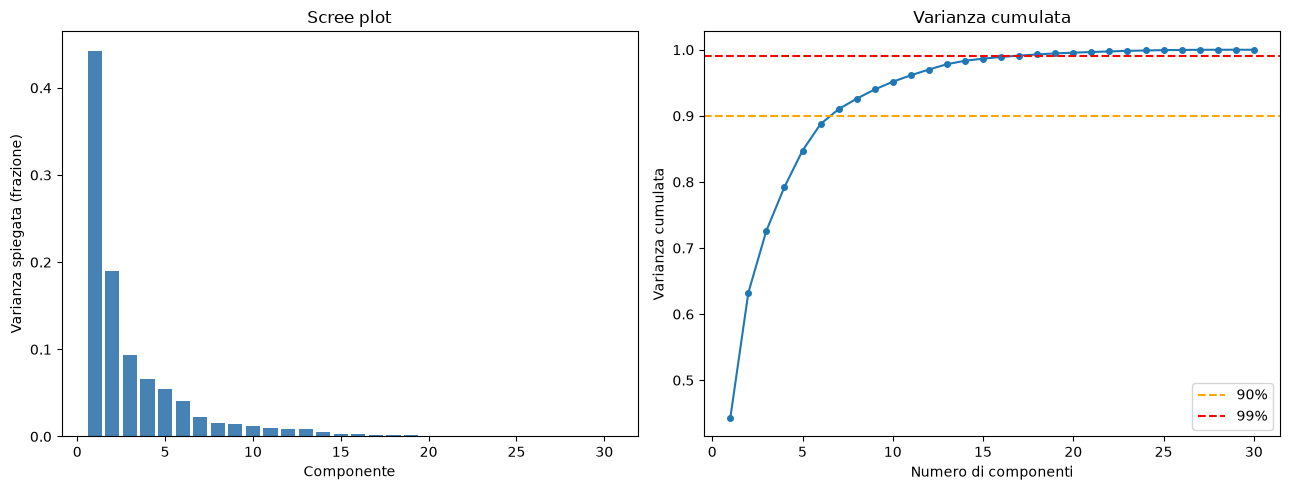


Top 3 feature nella PC1:
  mean concave points       peso = +0.261
  mean concavity            peso = +0.258
  worst concave points      peso = +0.251


In [18]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

cancer = load_breast_cancer()
X_std = StandardScaler().fit_transform(cancer.data)

pca = PCA().fit(X_std)
varianza = pca.explained_variance_ratio_
cumulata = np.cumsum(varianza)

n90 = np.argmax(cumulata >= 0.90) + 1
n99 = np.argmax(cumulata >= 0.99) + 1
print(f"Componenti per il 90% della varianza: {n90}")
print(f"Componenti per il 99% della varianza: {n99}")

# --- Scree plot e varianza cumulata ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
componenti = np.arange(1, len(varianza) + 1)

axes[0].bar(componenti, varianza, color="steelblue")
axes[0].set_title("Scree plot")
axes[0].set_xlabel("Componente")
axes[0].set_ylabel("Varianza spiegata (frazione)")

axes[1].plot(componenti, cumulata, marker="o", ms=4)
axes[1].axhline(0.90, color="orange", ls="--", label="90%")
axes[1].axhline(0.99, color="red", ls="--", label="99%")
axes[1].set_title("Varianza cumulata")
axes[1].set_xlabel("Numero di componenti")
axes[1].set_ylabel("Varianza cumulata")
axes[1].legend()
plt.tight_layout()
plt.show()

# --- Top 3 feature nella PC1 (peso in valore assoluto) ---
pesi_pc1 = pca.components_[0]
top3 = np.argsort(np.abs(pesi_pc1))[::-1][:3]
print("\nTop 3 feature nella PC1:")
for i in top3:
    print(f"  {cancer.feature_names[i]:<25} peso = {pesi_pc1[i]:+.3f}")


**Risposta:** servono **7** componenti per il 90% della varianza e **17** per il 99%: il dataset ha molta ridondanza, perché le 30 feature sono in gran parte correlate tra loro (raggio, perimetro e area misurano cose simili). Le feature più pesanti nella PC1 sono quelle sulla forma dei nuclei (`mean concave points`, `mean concavity`, `worst concave points`), con pesi tutti intorno a 0.25.

### Difficile
Obiettivo (esercizio del PDF): su `load_digits()` riduci i dati a 2 dimensioni con la PCA e visualizzali colorando per cifra. Poi confronta, con split stratificato, una `SVC` addestrata sui 64 pixel originali e una addestrata dopo PCA con 2, 10 e 30 componenti (sempre in Pipeline). Riporta accuratezza e tempo di addestramento e commenta il compromesso.

In [ ]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC

X, y = load_digits(return_X_y=True)

# --- 1) PCA a 2 dimensioni, colorato per cifra ---
X_2d = PCA(n_components=2).fit_transform(StandardScaler().fit_transform(X))
fig, ax = plt.subplots(figsize=(8, 6))
punti = ax.scatter(X_2d[:, 0], X_2d[:, 1], c=y, cmap="tab10", s=8)
fig.colorbar(punti, ax=ax, label="cifra")
ax.set_title("Digits: PCA a 2 componenti")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
plt.show()

# --- 2) SVC: 64 pixel originali vs PCA con 2, 10, 30 componenti (in Pipeline) ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

configurazioni = {
    "64 pixel originali": Pipeline([("scaler", StandardScaler()),
                                    ("svc", SVC())]),
}
for n in [2, 10, 30]:
    configurazioni[f"PCA {n} componenti"] = Pipeline([("scaler", StandardScaler()),
                                                      ("pca", PCA(n_components=n)),
                                                      ("svc", SVC())])

risultati = []
for nome, pipe in configurazioni.items():
    inizio = time.perf_counter()
    pipe.fit(X_train, y_train)                       # addestramento
    tempo = time.perf_counter() - inizio
    acc = pipe.score(X_test, y_test)
    risultati.append({"modello": nome,
                      "accuratezza": round(acc, 3),
                      "tempo_addestramento_s": round(tempo, 3)})

print(pd.DataFrame(risultati).to_string(index=False))


**Commento:** con 2 componenti l'accuratezza crolla al 53%: due assi non bastano per distinguere 10 cifre (il grafico 2D mostra le classi sovrapposte). Con 10 componenti si arriva al 95%, con 30 al 98%, quasi uguale ai 64 pixel originali (98%). Sui digits il tempo di addestramento è trascurabile e simile in tutti i casi (pochi centesimi di secondo, con variazioni tra un'esecuzione e l'altra); il vantaggio della riduzione diventa concreto con dataset più grandi o modelli più costosi. Il compromesso è quindi tra accuratezza e dimensionalità: 30 componenti perdono pochissimo rispetto a 64 feature, mentre la visualizzazione 2D è utile per capire la struttura dei dati ma non per classificare.

# 5.2 Riduzione non lineare e dati sparsi: Kernel PCA, t-SNE, Truncated SVD

## Spiegazione teorica

**Il limite della PCA:** trova solo assi **lineari** (rette). Se la struttura dei dati è curva (cerchi concentrici, spirali), proiettare su rette mescola i gruppi.

**Ripresa: il kernel (Giorno 3)**
- Un kernel misura la **somiglianza** tra due punti *come se* fossero in uno spazio di dimensione maggiore, dove relazioni curve diventano lineari, senza calcolare davvero quelle coordinate (**kernel trick**).
- Kernel comuni, con x e y due campioni e `x·y` il prodotto scalare (somma dei prodotti delle feature):
  - **lineare:** `K(x, y) = x·y` → equivale alla PCA normale;
  - **polinomiale:** `K(x, y) = (x·y + c)^d` → relazioni polinomiali di grado d;
  - **RBF / gaussiano:** `K(x, y) = exp(−gamma · ‖x − y‖²)` → somiglianza che decresce con la distanza; gamma ne regola la "larghezza";
  - **sigmoide:** `K(x, y) = tanh(α·x·y + c)`.

**Kernel PCA (`KernelPCA`)**
- Applica la PCA nello spazio "allargato" del kernel → coglie strutture non lineari.
- Parametri: `n_components`, `kernel` (`"linear"`, `"poly"`, `"rbf"`, `"sigmoid"`, `"cosine"`), `gamma`, `degree`; `fit_inverse_transform=True` per poter usare `inverse_transform`.
- Contro: più lenta della PCA (cresce con il quadrato del numero di campioni) e gamma va scelto con cura (cross-validation).

**t-SNE (`sklearn.manifold.TSNE`)**
- Tecnica non lineare pensata **solo per la visualizzazione** in 2D o 3D.
- Cerca di mantenere vicini i punti che erano vicini nello spazio originale (preserva le **relazioni locali**).
- Parametro principale: `perplexity` (circa "quanti vicini considerare", tipicamente 5–50).
- Limiti importanti:
  - non ha `transform`: non si può applicare a dati nuovi, quindi **non si usa come preprocessing** per un modello;
  - dimensioni dei gruppi e distanze **tra** gruppi nel grafico non hanno significato;
  - lenta su dataset grandi; risultato diverso a ogni esecuzione se non si fissa `random_state`.

**Dati sparsi e Truncated SVD (`TruncatedSVD`)**
- **Matrice sparsa:** tabella in cui quasi tutti i valori sono 0 (Giorno 2). Tipica dei testi: ogni colonna è una parola del vocabolario, ogni riga un documento, e ogni documento usa poche parole.
- **TF-IDF** (`TfidfVectorizer`, `sklearn.feature_extraction.text`): trasforma testi in numeri; ogni parola riceve un peso alto se è frequente nel documento ma rara negli altri (le parole che compaiono ovunque contano poco).
- La PCA deve **centrare** i dati (sottrarre la media), operazione che riempirebbe la matrice sparsa di valori diversi da zero, con un enorme spreco di memoria.
- `TruncatedSVD` riduce la dimensionalità **senza centrare** → lavora direttamente su matrici sparse. Applicata ai testi si chiama anche **LSA** (Latent Semantic Analysis) e fa emergere gli "argomenti" latenti.

**Come scegliere**
| Situazione | Metodo |
|---|---|
| Dati numerici, preprocessing per un modello, interpretabilità | PCA |
| Dataset troppo grande per la memoria | IncrementalPCA |
| Strutture non lineari, preprocessing per un modello | Kernel PCA |
| Solo visualizzazione di gruppi/cluster | t-SNE |
| Dati sparsi (testi, conteggi) | TruncatedSVD |

## Esempi teorici di utilizzo

- **Kernel PCA:** dati di sensori con relazioni non lineari, prima di un classificatore lineare veloce.
- **t-SNE:** esplorare un dataset di migliaia di immagini o di profili clienti per vedere se emergono gruppi naturali, prima di fare clustering.
- **TruncatedSVD su testi:** ridurre migliaia di parole a 100 "argomenti" per classificare ticket di assistenza o recensioni.
- **IncrementalPCA:** milioni di righe di log letti a blocchi da disco.

## Esempi di codice

### Base
Cosa mostra: la PCA non separa due cerchi concentrici, la Kernel PCA sì.

In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles
from sklearn.decomposition import PCA, KernelPCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

X, y = make_circles(n_samples=400, noise=0.05, factor=0.3, random_state=0)   # cerchio interno ed esterno

X_pca = PCA(n_components=2).fit_transform(X)
X_kpca = KernelPCA(n_components=2, kernel="rbf", gamma=5).fit_transform(X)

for nome, Z in [("PCA", X_pca), ("Kernel PCA", X_kpca)]:
    acc = cross_val_score(LogisticRegression(), Z, y, cv=5).mean()     # classificatore LINEARE
    print(f"{nome:10s} accuratezza della regressione logistica: {acc:.2f}")

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, Z, titolo in zip(axes, [X, X_pca, X_kpca], ["Originale", "PCA", "Kernel PCA (rbf)"]):
    ax.scatter(Z[:, 0], Z[:, 1], c=y, cmap="coolwarm", s=12); ax.set_title(titolo)
plt.show()

- La PCA ruota soltanto i dati: i cerchi restano concentrici e un modello lineare non li separa (accuratezza intorno a 0.45, come tirare a indovinare).
- Dopo la Kernel PCA i due cerchi diventano separabili da una retta: la regressione logistica arriva a 1.00.
- Il lavoro "non lineare" lo fa la trasformazione; il modello successivo può restare semplice.

### Intermedio
Cosa mostra: confronto tra PCA e t-SNE per visualizzare le 10 cifre di Digits.

In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

X, y = load_digits(return_X_y=True)

X_pca = PCA(n_components=2).fit_transform(X)
X_tsne = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(X)   # solo fit_transform

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, Z, titolo in zip(axes, [X_pca, X_tsne], ["PCA", "t-SNE"]):
    punti = ax.scatter(Z[:, 0], Z[:, 1], c=y, cmap="tab10", s=8)
    ax.set_title(titolo)
fig.colorbar(punti, ax=axes, label="cifra")
plt.show()

- Con la PCA le cifre si sovrappongono molto: due componenti lineari non bastano per 10 classi.
- Con t-SNE emergono 10 gruppi ben distinti: le cifre simili restano vicine.
- t-SNE serve per **guardare** i dati: per addestrare un modello si usa la PCA (che ha `transform`).
- Il calcolo di t-SNE richiede qualche secondo: su dataset grandi conviene campionare le righe.

### Avanzato
Cosa mostra: TruncatedSVD su testi trasformati con TF-IDF, per far emergere gli argomenti.

In [ ]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD

frasi = [
    "la squadra ha vinto la partita di calcio",
    "il calciatore ha segnato un gol nella partita",
    "l'allenatore prepara la squadra per il campionato",
    "il tifoso guarda la partita allo stadio",
    "la ricetta della pasta richiede pomodoro e basilico",
    "il cuoco prepara la pasta con il pomodoro",
    "una ricetta veloce per una cena con la pasta",
    "il forno cuoce la pizza con pomodoro e mozzarella",
]
parole_vuote = ["la", "il", "di", "un", "una", "e", "per", "con", "della", "nella", "allo", "ha", "l"]

tfidf = TfidfVectorizer(stop_words=parole_vuote)      # ignora le parole senza contenuto
X = tfidf.fit_transform(frasi)                        # matrice SPARSA: righe = frasi, colonne = parole
print("Forma:", X.shape, "| valori diversi da zero:", X.nnz, "su", X.shape[0] * X.shape[1])

svd = TruncatedSVD(n_components=2, random_state=0)
X_svd = svd.fit_transform(X)                          # lavora sulla matrice sparsa senza centrarla
parole = tfidf.get_feature_names_out()
for i, comp in enumerate(svd.components_):
    print(f"Componente {i}: parole più pesanti ->", parole[np.argsort(np.abs(comp))[-4:]])
for frase, coord in zip(frasi, X_svd.round(2)):
    print(coord, frase)

- La matrice TF-IDF è quasi tutta vuota: per questo si usa TruncatedSVD e non la PCA.
- Le componenti diventano "argomenti": una raccoglie le parole del calcio, l'altra quelle della cucina.
- Le coordinate delle frasi mostrano a quale argomento appartiene ciascuna, senza aver mai fornito etichette.
- `stop_words` elimina parole che compaiono ovunque e non distinguono i temi.

## Esercizi

### Facile
Obiettivo: genera `make_moons(n_samples=300, noise=0.05, random_state=0)` e applica `KernelPCA(kernel="rbf")` con gamma 0.1, 1, 15. Disegna i tre risultati affiancati e indica quale valore "apre" meglio le due mezzelune.

In [ ]:
# Scrivi qui la tua soluzione


### Medio
Obiettivo: su `load_breast_cancer()` (standardizzato) visualizza i dati con PCA e con t-SNE (`perplexity` 5, 30, 50), colorando per diagnosi. In quale rappresentazione le due classi sono più separate? Perché non useresti l'output di t-SNE come input di un classificatore?

In [ ]:
# Scrivi qui la tua soluzione


### Difficile
Obiettivo: scrivi 16 frasi brevi su quattro argomenti (es. viaggi, tecnologia, salute, musica), trasformale con `TfidfVectorizer`, riducile a 2 e a 4 componenti con `TruncatedSVD` e stampa per ogni componente le 5 parole più pesanti. Poi applica `KMeans` (modulo 5.3) sulle 4 componenti e verifica se i gruppi trovati corrispondono agli argomenti.

In [ ]:
# Scrivi qui la tua soluzione


# 5.3 Clustering

## Spiegazione teorica

**Obiettivo:** raggruppare i campioni in **cluster** (gruppi) di elementi simili tra loro e diversi da quelli degli altri gruppi, **senza etichette**. Il modello riceve solo X.
- "Simile" significa quasi sempre **vicino** (distanza euclidea): lo **scaling** è necessario, come per KNN.
- Il risultato è un'etichetta per campione (`labels_`). I numeri dei cluster sono **arbitrari**: il cluster "0" non corrisponde necessariamente alla classe "0".

**K-Means**
1. Si sceglie il numero di cluster **k**.
2. Si posizionano k **centroidi** iniziali (il "centro" di ogni cluster).
3. Ogni punto viene assegnato al centroide più vicino.
4. Ogni centroide viene spostato nella **media** dei punti assegnati.
5. Si ripetono i passi 3–4 finché i centroidi non si spostano più (convergenza).
- **Inerzia** (`inertia_`): somma delle distanze al quadrato di ogni punto dal suo centroide. Più è bassa, più i cluster sono compatti; ma **diminuisce sempre** aumentando k (con k = numero di punti è 0), quindi non basta per scegliere k.
- Parametri di classe o ipeparametri:
  - `n_clusters` (default 8): k;
  - `init="k-means++"` (default): sceglie centroidi iniziali distanti tra loro → convergenza più rapida e risultati migliori di `"random"`;
  - `n_init`: quante volte ripetere l'algoritmo con centroidi iniziali diversi, tenendo il risultato con inerzia minore (dalla versione 1.4 il default è `"auto"`);
  - `max_iter` (default 300), `tol` (tolleranza per dichiarare la convergenza), `random_state`.
- `cluster_centers_`: coordinate dei centroidi; `predict` assegna nuovi punti al centroide più vicino.
- Limiti: bisogna scegliere k; trova bene solo cluster "tondeggianti" e di dimensioni simili; sensibile a outlier e scala.

**Scegliere k**
- **Metodo del gomito (elbow):** si disegna l'inerzia al variare di k e si cerca il punto in cui la curva smette di scendere rapidamente (il "gomito").
- **Coefficiente di silhouette** (`silhouette_score`): per ogni punto confronta `a` = distanza media dai punti del **proprio** cluster e `b` = distanza media dai punti del cluster **più vicino**: `s = (b − a) / max(a, b)`.
  - vicino a 1 → punto ben dentro il suo cluster; vicino a 0 → al confine; negativo → probabilmente nel cluster sbagliato.
  - Si sceglie il k con la silhouette media più alta.

**Clustering agglomerativo (gerarchico)**
- Parte con ogni punto come cluster a sé e **unisce** a ogni passo i due cluster più vicini, finché ne restano `n_clusters`.
- `linkage` = come si misura la distanza tra due cluster:
  - `"ward"` (default): unisce i cluster che aumentano di meno la varianza interna (cluster compatti, simile a K-Means);
  - `"complete"`: distanza tra i due punti più lontani;
  - `"average"`: distanza media tra tutte le coppie;
  - `"single"`: distanza tra i due punti più vicini (segue forme allungate, ma sensibile al rumore).
- Il **dendrogramma** (`scipy.cluster.hierarchy`) disegna l'intera sequenza di unioni: tagliandolo a diverse altezze si ottengono diversi numeri di cluster.
- Non ha `predict` per nuovi punti.

**DBSCAN (clustering basato sulla densità)**
- Un cluster è una zona **densa** di punti.
  - `eps`: raggio dell'intorno di un punto;
  - `min_samples`: punti minimi nell'intorno perché un punto sia **centrale** (core point).
- I punti centrali vicini formano un cluster; i punti raggiungibili ma non centrali sono di **bordo**; quelli isolati sono **rumore** ed etichettati **−1**.
- Pro: non serve indicare k; trova cluster di **forma qualsiasi**; individua gli outlier.
- Contro: molto sensibile a `eps`; in difficoltà se i cluster hanno densità diverse; non ha `predict`.
- (Il PDF cita anche Mean-Shift: un altro metodo basato sulla densità, che sposta i centri verso le zone più dense; meno usato.)

**Valutare il clustering**
- Senza etichette vere (caso reale): inerzia, silhouette e interpretazione dei cluster da parte di un esperto.
- Con etichette vere (dataset didattici come Iris), per confrontare cluster e classi:
  - **Adjusted Rand Index** (`adjusted_rand_score`): 1 = cluster identici alle classi, circa 0 = assegnazione casuale; non dipende dai numeri usati per i cluster;
  - **Omogeneità** (`homogeneity_score`): ogni cluster contiene una sola classe?
  - **Completezza** (`completeness_score`): ogni classe finisce in un solo cluster? La **V-measure** è la loro media armonica.

## Esempi teorici di utilizzo

- **Segmentazione dei clienti:** gruppi con comportamenti d'acquisto simili per campagne di marketing mirate (K-Means).
- **Rilevamento di anomalie:** transazioni o letture di sensori che DBSCAN marca come rumore (−1) sono candidate frodi o guasti.
- **Dati geografici:** zone ad alta concentrazione di incidenti o di richieste di servizio, di forma irregolare (DBSCAN).
- **Tassonomie:** organizzare prodotti o documenti in una gerarchia di categorie (agglomerativo + dendrogramma).

## Esempi di codice

### Base
Cosa mostra: K-Means su dati sintetici, centroidi e assegnazione di un nuovo punto.

Centroidi:
 [[ 1.98  0.87]
 [ 0.95  4.42]
 [-1.37  7.75]
 [-1.58  2.83]]
Inerzia: 212.0
Nuovo punto [0, 4] -> cluster [1]


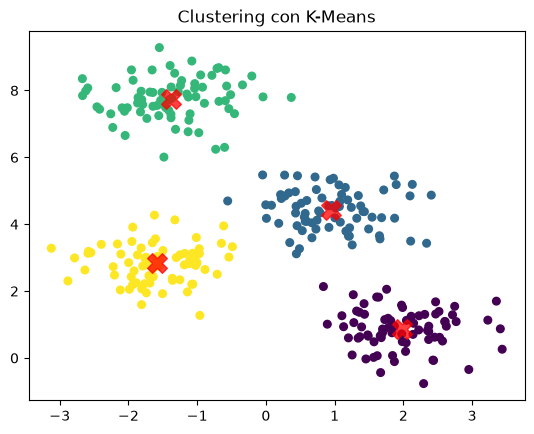

In [5]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

X, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=0)    # ignoriamo le etichette

kmeans = KMeans(n_clusters=4, init="k-means++", n_init=10, random_state=42)
etichette = kmeans.fit_predict(X)                                                # fit + etichetta di ogni punto

print("Centroidi:\n", kmeans.cluster_centers_.round(2))
print("Inerzia:", round(kmeans.inertia_, 1))
print("Nuovo punto [0, 4] -> cluster", kmeans.predict([[0, 4]]))

plt.scatter(X[:, 0], X[:, 1], c=etichette, s=30, cmap="viridis")
plt.scatter(*kmeans.cluster_centers_.T, c="red", s=200, alpha=0.75, marker="X")   # centroidi
plt.title("Clustering con K-Means"); plt.show()

- `fit_predict` addestra e restituisce subito il cluster di ogni punto (equivale a `fit` + `labels_`).
- I centroidi sono la media dei punti di ciascun cluster.
- `predict` assegna un punto nuovo al centroide più vicino: utile per classificare nuovi clienti in segmenti esistenti.

### Intermedio
Cosa mostra: scegliere k con il metodo del gomito e con la silhouette.

k=2: inerzia=   15386  silhouette=0.607
k=3: inerzia=    3125  silhouette=0.782
k=4: inerzia=     607  silhouette=0.834
k=5: inerzia=     548  silhouette=0.701
k=6: inerzia=     492  silhouette=0.586
k=7: inerzia=     436  silhouette=0.456
k=8: inerzia=     380  silhouette=0.347


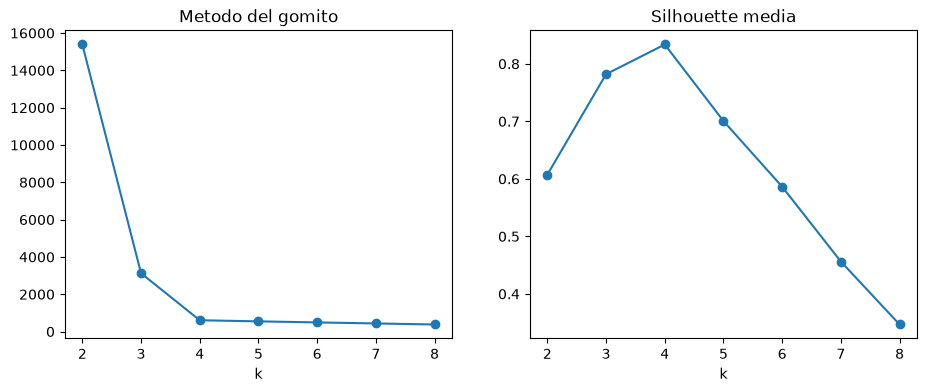

In [6]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X, _ = make_blobs(n_samples=500, centers=4, cluster_std=0.8, random_state=42)

valori_k = range(2, 9)
inerzie, silhouette = [], []
for k in valori_k:
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X)
    inerzie.append(km.inertia_)
    silhouette.append(silhouette_score(X, km.labels_))      # media su tutti i punti
    print(f"k={k}: inerzia={km.inertia_:8.0f}  silhouette={silhouette[-1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(valori_k, inerzie, "o-"); axes[0].set_title("Metodo del gomito"); axes[0].set_xlabel("k")
axes[1].plot(valori_k, silhouette, "o-"); axes[1].set_title("Silhouette media"); axes[1].set_xlabel("k")
plt.show()

- L'inerzia scende sempre, ma dopo k = 4 scende molto meno: il "gomito" è a 4.
- La silhouette ha il massimo proprio a k = 4: i due criteri concordano.
- Su dati reali i criteri possono non essere netti: la scelta finale considera anche il significato dei gruppi.

### Avanzato
Cosa mostra: confronto tra K-Means, agglomerativo e DBSCAN su cluster non sferici.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.preprocessing import St### Medio
Obiettivo (esercizio del PDF): su `load_iris()` applica K-Means con 3 cluster sulle 4 feature standardizzate, visualizza i cluster sulle prime due componenti della PCA e confronta con le specie vere usando `adjusted_rand_score`, `homogeneity_score` e una tabella `pd.crosstab(specie, cluster)`. Quale specie viene confusa di più?andardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import adjusted_rand_score

X, y_vere = make_moons(n_samples=300, noise=0.06, random_state=0)
X = StandardScaler().fit_transform(X)                  # le distanze richiedono la stessa scala

algoritmi = {
    "K-Means (k=2)": KMeans(n_clusters=2, n_init=10, random_state=0),
    "Agglomerativo ward": AgglomerativeClustering(n_clusters=2, linkage="ward"),
    "Agglomerativo single": AgglomerativeClustering(n_clusters=2, linkage="single"),
    "DBSCAN eps=0.3": DBSCAN(eps=0.3, min_samples=5),
    "DBSCAN eps=0.5": DBSCAN(eps=0.5, min_samples=5),
}
fig, axes = plt.subplots(1, len(algoritmi), figsize=(20, 4))
for ax, (nome, alg) in zip(axes, algoritmi.items()):
    etichette = alg.fit_predict(X)
    ari = adjusted_rand_score(y_vere, etichette)       # confronto con le "vere" mezzelune
    n_rumore = int(np.sum(etichette == -1))            # DBSCAN: -1 = rumore
    ax.scatter(X[:, 0], X[:, 1], c=etichette, cmap="viridis", s=12)
    ax.set_title(f"{nome}\nARI={ari:.2f} rumore={n_rumore}")
    print(f"{nome:22s} ARI={ari:.3f} cluster trovati={sorted(int(e) for e in set(etichette))}")
plt.show()

- K-Means e ward tagliano le mezzelune con una linea: cercano gruppi compatti e tondeggianti.
- Il linkage `single` e DBSCAN seguono la forma curva e ritrovano le due mezzelune (ARI 1.00 e 0.99; DBSCAN marca come rumore un punto isolato).
- DBSCAN con `eps=0.5` unisce tutto in un solo cluster (ARI 0): il raggio è troppo grande. `eps` va scelto con attenzione.
- L'ARI qui si può calcolare solo perché conosciamo le etichette vere; nei casi reali non ci sono.

## Esercizi

### Facile
Obiettivo: genera `make_blobs(n_samples=400, centers=3, cluster_std=1.0, random_state=7)`, applica K-Means con k = 3, disegna punti e centroidi e calcola la silhouette media. Ripeti con k = 2 e k = 5 e confronta le silhouette.

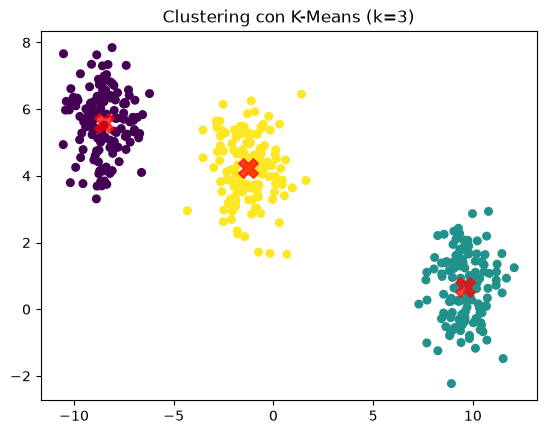

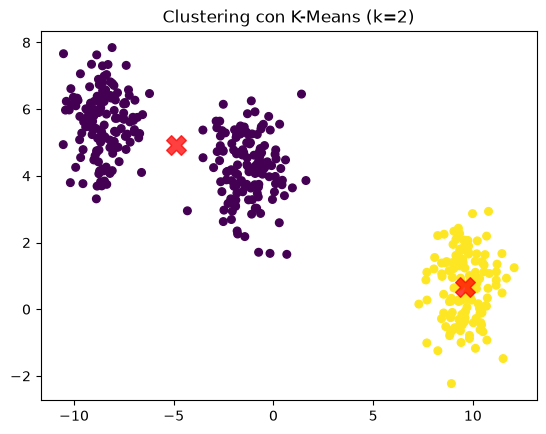

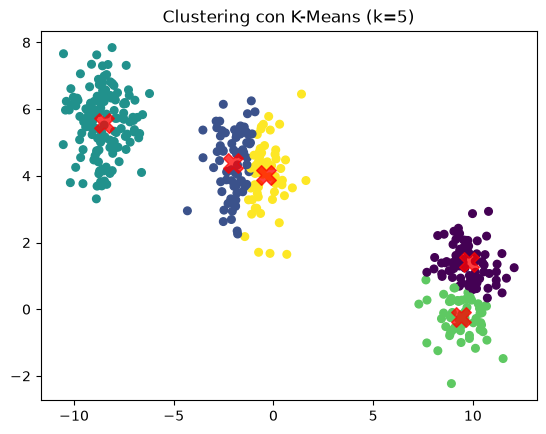

    s_score
K          
3  0.792340
2  0.743463
5  0.478486


In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

X, _ = make_blobs(n_samples=400, centers=3, cluster_std=1.00, random_state=7)    # ignoriamo le etichette

k_values = [3, 2, 5]
sil_score = []

for  i in k_values:
    
    kmeans = KMeans(n_clusters=i, init="k-means++", n_init=10, random_state=42)
    etichette = kmeans.fit_predict(X)                                                # fit + etichetta di ogni punto

    sil_score.append(silhouette_score(X, kmeans.labels_))

    plt.scatter(X[:, 0], X[:, 1], c=etichette, s=30, cmap="viridis")
    plt.scatter(*kmeans.cluster_centers_.T, c="red", s=200, alpha=0.75, marker="X")   # centroidi
    plt.title(f"Clustering con K-Means (k={i})"); plt.show()
    

df = pd.DataFrame({
    "K" : k_values,
    "s_score": sil_score
})
df = df.set_index("K")
print(df)

### Medio
Obiettivo: su `load_iris()` standardizza le 4 feature e applica K-Means con k da 2 a 8. Per ogni k salva l'inerzia e la silhouette media, poi disegna i due grafici affiancati (gomito e silhouette). Quale k suggerisce ciascun criterio? I due criteri concordano? Il valore scelto coincide con le 3 specie di iris?

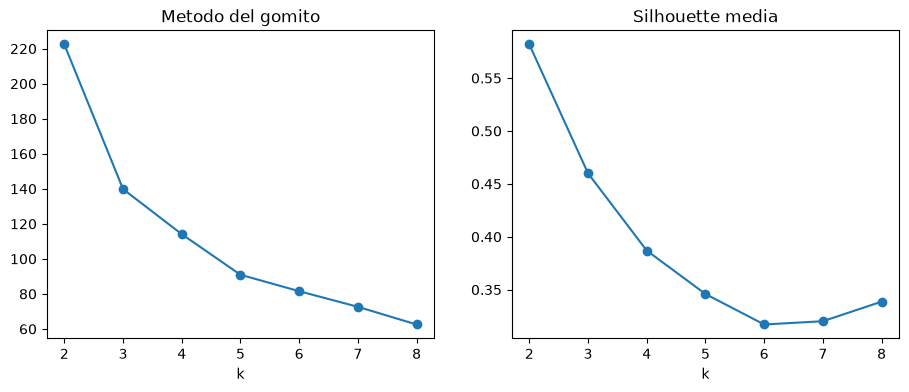

[222.36170496502308, 139.8204963597498, 114.09254690403088, 90.92751382392052, 81.54439095511783, 72.63114382667189, 62.540605695781224]

[0.5817500491982808, 0.45994823920518635, 0.38694104154427816, 0.3459012795948778, 0.31707940193569023, 0.3201967939183684, 0.33869173894897225]


In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

import pandas as pd

iris = load_iris()
X_scaled = StandardScaler().fit_transform(iris.data)

k_values =  list(range(2, 9))

inr_score = []
sil_score = []

for i in k_values:
    kmeans = KMeans(n_clusters=i, init="k-means++", n_init=10, random_state=42).fit(X_scaled)
    sil_score.append(silhouette_score(X_scaled, kmeans.labels_))
    inr_score.append(kmeans.inertia_)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(k_values,  inr_score, "o-"); axes[0].set_title("Metodo del gomito"); axes[0].set_xlabel("k")
axes[1].plot(k_values,  sil_score, "o-"); axes[1].set_title("Silhouette media"); axes[1].set_xlabel("k")
plt.show()

#print(inr_score)
#print("")
#print(sil_score)    

#Il metodo del gomito suggerisce k = 3; Silhouette media suggerisce k = 2; i due metodi non concordano
#Il metodo del gomito suggerisce un valore che coincide con il numero delle specie reali.     



### Difficile
Obiettivo: su `load_wine()` (standardizzato) confronta K-Means, agglomerativo (ward, complete, average) e DBSCAN. Per DBSCAN prova una griglia di `eps` (0.5–3.0) e `min_samples` (3–10) e riporta numero di cluster trovati, punti di rumore e silhouette. Disegna il dendrogramma con `scipy.cluster.hierarchy.dendrogram(linkage(X, "ward"))` e indica a quale altezza tagliarlo per ottenere 3 cluster. Quale metodo ritrova meglio le 3 classi di vino (ARI)?

In [ ]:
# Scrivi qui la tua soluzione
